# 🔍 [AI 트랙] XAI 과제 — 내 모델은 어디를 보고 있을까?

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">🎯 과제 목적</b><br>수업에서 배운 XAI 기법(Grad-CAM · LIME · SHAP)을 <b>직접 구현하고 적용</b>해 봅니다. 핵심은 코드를 완성하는 것이 아니라, <b>두 기법이 같은 이미지에 대해 내놓는 설명을 비교하고, 왜 그런 차이가 나는지 수업 내용(분류 축: Gradient vs Perturbation)으로 해석하는 것</b>입니다. 각자 학번 기반 시드로 <b>서로 다른 이미지</b>가 배정되므로, 남의 답을 복사하면 해석이 어긋납니다. 마지막에는 '설명 자체를 의심하는' sanity check까지 경험합니다.</div>


<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">✍️ 기술 블로그 연결 (꼭 읽어주세요!)</b><br>이 과제의 결과물은 여러분의 <b>논문 리뷰 기술 블로그</b>와 연결됩니다.<br><b>문제 1.3(Grad-CAM 클래스별 히트맵), 1.4~1.5(LIME 실험과 Grad-CAM 비교), 심화 2.2(sanity check)</b>의 결과 그래프와 여러분의 해석을 블로그에 옮겨 작성해 주세요. LIME 논문(Why Should I Trust You?) 리뷰에 '내가 직접 돌려본 LIME' 섹션이 들어가면 훨씬 좋은 글이 됩니다.</div>


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">🤖 생성형 AI 사용 규칙</b><br>GPT/Claude 사용 <b>허용</b>합니다. 단 ① 에러 해결·문법 질문에 쓰는 것은 자유, ② <b>해석·비교·결론은 반드시 본인의 문장</b>으로 쓸 것 (실험 결과는 각자 다르므로 AI가 대신 써줄 수 없습니다), ③ <b>마지막 '3. 생성형 AI 활용 기록' 셀에 사용 내역과 대화 내용을 꼭 남길 것.</b> 기록 없이 AI 문체만 남은 답안은 감점됩니다.</div>

---
**제출물**: 이 노트북 완성본(.ipynb) 1개 — 모든 셀 실행 결과가 남아 있는 상태로 제출


## 📋 목차

| 번호 | 내용 | 난이도 |
|---|---|---|
| **0** | 환경 설정 — 라이브러리 · 내 시드 · 이미지 배정 | 🟢 |
| **1.1** | 사전학습 CNN 준비, 배정 이미지 예측 확인 | 🟢 |
| **1.2** | **Grad-CAM 직접 구현** (hook + α 계산 + ReLU) | 🔴 핵심 |
| **1.3** | 클래스별 히트맵 비교 실험과 해석 | 🟡 |
| **1.4** | LIME 적용 — 하이퍼파라미터 · 불안정성 실험 | 🟡 |
| **1.5** | Grad-CAM vs LIME 종합 비교 (서술) | 🟡 |
| **2.1** | (심화) SHAP — 표 데이터에서 Local↔Global | 🟡 선택 |
| **2.2** | (심화) Sanity Check — 설명을 의심하기 | 🔴 선택 |
| **3** | 생성형 AI 활용 기록 (**필수 제출**) | — |
| **4** | 회고 | — |


# 0. 환경 설정

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">💡 시작 전에</b><br>런타임 유형을 <b>GPU</b>로 바꿔주세요 (상단 메뉴: 런타임 → 런타임 유형 변경 → T4 GPU). CPU로도 돌아가지만 LIME 실험(1.4)이 오래 걸립니다.<br>아래 설치·다운로드 셀은 처음 한 번만 실행하면 됩니다 (1~2분 소요).</div>

In [ ]:
# 라이브러리 설치 (Colab 기본 환경에 없는 것만)
!pip -q install lime shap

# 실습용 이미지: ImageNet 1000개 클래스에서 클래스당 1장씩 모아둔 공개 저장소
!if [ ! -d imagenet-sample-images ]; then git clone -q --depth 1 https://github.com/EliSchwartz/imagenet-sample-images.git; fi
!ls imagenet-sample-images | head -3


In [2]:
import os, random, copy
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)   # 'cuda'가 아니면 런타임 유형을 확인하세요


사용 장치: cpu


In [3]:
# ──────────────────────────────────────────────
#  내 실험 조건 만들기 : 학번이 곧 나의 시드!
#  (같은 시드 = 같은 이미지 배정. 답안이 서로 다른 이유입니다)
# ──────────────────────────────────────────────
STUDENT_ID = 1347   # TODO: 본인 학번을 숫자로 입력하세요 (예: 2271234)

assert STUDENT_ID != 0, "본인 학번을 입력해 주세요!"
SEED = STUDENT_ID % 10000
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"나의 실험 시드: {SEED}")


나의 실험 시드: 1347


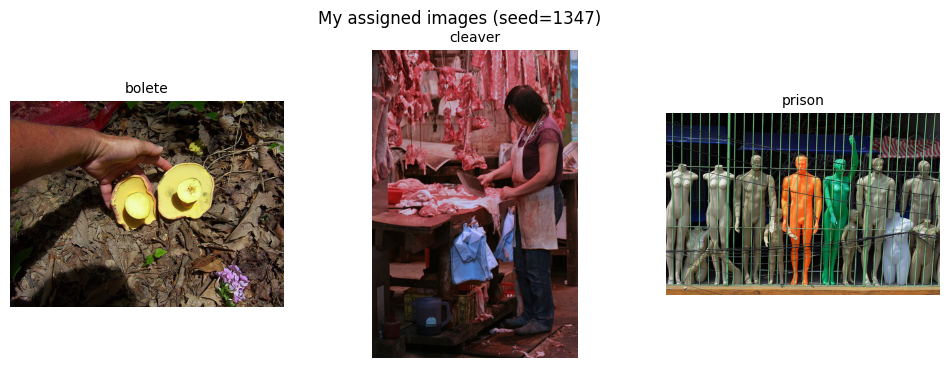

In [4]:
# 시드로 나만의 이미지 3장 배정받기
IMG_DIR = "imagenet-sample-images"
all_files = sorted(f for f in os.listdir(IMG_DIR) if f.upper().endswith(".JPEG"))
my_files = random.Random(SEED).sample(all_files, 3)

my_images = [Image.open(os.path.join(IMG_DIR, f)).convert("RGB") for f in my_files]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, name in zip(axes, my_images, my_files):
    ax.imshow(img); ax.axis("off")
    ax.set_title(name.split("_", 1)[-1].replace(".JPEG", ""), fontsize=10)
# 그래프 안 텍스트는 영문 사용 — Colab 기본 폰트에 한글이 없어 □로 깨집니다
plt.suptitle(f"My assigned images (seed={SEED})")
plt.show()


# 1. 필수 과제

## 1.1 사전학습 CNN 준비 — 모델은 내 이미지를 뭐라고 볼까?

ImageNet으로 학습된 **ResNet-18**을 불러와서, 배정받은 이미지 3장에 대한 **top-5 예측**을 확인합니다.
이 예측 결과가 이후 모든 문제의 출발점이 됩니다. *(이 단계는 코드가 거의 완성되어 있어요 — 주석 빈칸만 채우면 됩니다)*

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💬 주석 빈칸이란?</b><br>코드 중간의 <code># (빈칸 A) ...</code> 주석을 채우는 문제입니다. '내가 지금 어느 단계의 무엇을 하고 있는지'를 스스로 설명할 수 있어야 나중에 코드를 응용할 수 있기 때문에 넣었습니다. 한 줄이면 충분합니다!</div>

In [5]:
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).to(device).eval()   # (빈칸 A) .eval()을 호출하는 이유는? → Dropout을 끄고 BatchNorm이 배치 통계 대신 학습된 이동평균을 쓰게 해, 같은 입력이면 항상 같은 출력이 나오도록 추론 모드로 고정
categories = weights.meta["categories"]               # ImageNet 1000개 클래스 이름
preprocess = weights.transforms()                     # (빈칸 B) 이 전처리가 하는 일 두 가지는? → ① Resize+CenterCrop으로 224x224 크기를 맞추고 ② ImageNet 평균/표준편차로 정규화 (학습 때와 같은 입력 분포를 만들기 위함)

def predict_probs(img_pil):
    """PIL 이미지 → 1000개 클래스 확률 (torch.Tensor, shape [1000])"""
    x = preprocess(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():                             # (빈칸 C) 여기서 no_grad를 쓰는 이유는? → 예측만 할 뿐 역전파가 필요 없으므로, 계산 그래프를 만들지 않아 메모리와 연산을 아끼기 위해
        logits = model(x)
    return F.softmax(logits, dim=1)[0].cpu()

for name, img in zip(my_files, my_images):
    probs = predict_probs(img)
    top5 = probs.topk(5)
    print(f"\n📷 {name}")
    for p, idx in zip(top5.values, top5.indices):
        print(f"   {categories[idx]:30s} {p*100:5.1f}%")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ji sung min/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

  2%|▏         | 896k/44.7M [00:00<00:18, 2.45MB/s]

  3%|▎         | 1.38M/44.7M [00:00<00:16, 2.72MB/s]

  4%|▍         | 1.75M/44.7M [00:00<00:23, 1.95MB/s]

...

 99%|█████████▉| 44.2M/44.7M [00:38<00:00, 1.06MB/s]

 99%|█████████▉| 44.4M/44.7M [00:38<00:00, 1.09MB/s]

100%|█████████▉| 44.6M/44.7M [00:38<00:00, 1.29MB/s]

100%|██████████| 44.7M/44.7M [00:38<00:00, 1.20MB/s]


📷 n13054560_bolete.JPEG
   bolete                          56.3%
   jackfruit                       35.8%
   sulphur butterfly                3.0%
   yellow lady's slipper            1.6%
   lemon                            0.8%

📷 n03041632_cleaver.JPEG
   butcher shop                    99.7%
   cleaver                          0.2%
   grocery store                    0.0%
   handkerchief                     0.0%
   mosquito net                     0.0%

📷 n04005630_prison.JPEG
   prison                          60.7%
   macaw                            9.8%
   langur                           2.1%
   fountain                         2.1%
   bow                              1.8%


## 1.2 🔴 Grad-CAM 직접 구현 — 이 과제의 포인트

수업에서 배운 5단계 파이프라인을 그대로 코드로 옮깁니다. 라이브러리(`pytorch-grad-cam` 등)를 쓰지 않고
**hook으로 직접** 구현하는 것이 포인트입니다.

> **수업 복습** — ① Forward로 클래스 점수 $y^c$ 계산 → ② $y^c$를 마지막 conv의 feature map $A^k$까지 backward →
> ③ gradient를 공간 평균해 채널 가중치 $\alpha_k^c$ → ④ $\sum_k \alpha_k^c A^k$ 후 ReLU → ⑤ 입력 크기로 upsample

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 힌트</b><br>· hook은 '모델이 계산하는 중간 값을 몰래 저장하는 장치'입니다. forward hook은 활성값 A^k를, backward hook은 ∂y^c/∂A^k를 잡아둡니다 (둘 다 코드로 제공됨).<br>· <b>TODO 1</b>: gradient 텐서 shape은 [1, K, h, w]. 공간 축(h, w)에 대해 평균하면 α가 됩니다 → <code>mean(dim=?)</code><br>· <b>TODO 2</b>: α(shape [1,K,1,1])와 activations([1,K,h,w])를 곱해 채널 축으로 합한 뒤 ReLU → 수업의 2×2 손계산 예제와 같은 연산!<br>· 잘 됐는지 확인: 다음 셀의 시각화에서 히트맵이 물체 위에 얹혀야 정상입니다.</div>

In [6]:
class GradCAM:
    """수업의 5단계 파이프라인을 그대로 구현한 최소 Grad-CAM"""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None   # A^k  가 저장될 자리
        self.gradients = None     # ∂y^c/∂A^k 가 저장될 자리
        # hook 등록: forward/backward 때 중간값을 가로채 저장
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()          # shape [1, K, h, w]

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()    # shape [1, K, h, w]

    def __call__(self, x, class_idx=None):
        # ① Forward — 클래스 점수 계산
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()

        # ② Backward — 선택한 클래스 점수만 미분
        score = logits[0, class_idx]
        score.backward()

        # ③ 채널 가중치 α_k^c 계산
        # (빈칸 D) 이 줄이 수업 슬라이드의 어떤 수식에 해당하는지 쓰세요 → α_k^c = (1/Z)·ΣiΣj ∂y^c/∂A_ij^k  (채널 k의 gradient를 h×w 공간 전체에 대해 평균낸 Global Average Pooling)
        alpha = self.gradients.mean(dim=(2, 3), keepdim=True)   # TODO 1: self.gradients 를 공간 축에 대해 평균 (keepdim=True 권장)

        # ④ 가중합 + ReLU
        # (빈칸 E) ReLU를 마지막에 적용하는 이유는? → 해당 클래스 점수를 '올리는' 양의 기여만 보고 싶기 때문. 음수는 다른 클래스를 지지하는 영역이라 잘라내지 않으면 히트맵이 흐려진다
        cam = F.relu((alpha * self.activations).sum(dim=1))     # TODO 2: (alpha * self.activations)를 채널 축으로 합한 뒤 F.relu

        # ⑤ 정규화 + 입력 크기로 upsample (완성되어 있음)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = F.interpolate(cam.unsqueeze(0), size=x.shape[-2:],
                            mode="bilinear", align_corners=False)
        return cam[0, 0].cpu().numpy(), class_idx

# 마지막 conv 블록(layer4의 마지막 BasicBlock)에 hook을 겁니다
gradcam = GradCAM(model, model.layer4[-1])
print("GradCAM 준비 완료")


GradCAM 준비 완료


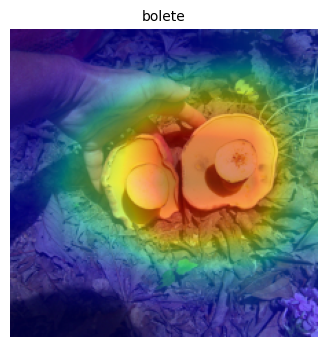

In [7]:
# 시각화 도우미 (완성 코드 — 그대로 실행)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

def to_numpy_img(x):
    """정규화된 텐서[3,H,W] → 화면 표시용 numpy[H,W,3]"""
    return (x.cpu() * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

def show_gradcam(img_pil, class_idx=None, ax=None, title=None):
    x = preprocess(img_pil).unsqueeze(0).to(device)
    cam, used_idx = gradcam(x, class_idx)
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(to_numpy_img(x[0])); ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.axis("off"); ax.set_title(title or categories[used_idx], fontsize=10)
    return used_idx

# 동작 확인: 첫 번째 배정 이미지의 top-1 히트맵
show_gradcam(my_images[0])
plt.show()


## 1.3 실험 — 같은 이미지, 다른 클래스로 미분하면?

Grad-CAM의 매력은 **class-discriminative**, 즉 "어느 클래스 입장에서 보는가"를 우리가 고를 수 있다는 점이었죠
(수업의 Cat/Dog 그림). 내 이미지 3장 각각에 대해 **top-1 클래스 히트맵과 top-2 클래스 히트맵**을 나란히 그려 비교하세요.

**해야 할 일**
1. 아래 셀을 완성해 3장 × (원본 | top-1 CAM | top-2 CAM) 그리드를 그린다
2. 그림 아래 답안 셀에 해석을 쓴다 — *top-1과 top-2 히트맵이 다른 곳을 비추는 이미지가 있나요? 그 이유는 무엇일까요?
모델이 엉뚱한 곳(배경 등)을 보는 경우가 있다면 그것은 무엇을 시사하나요?*

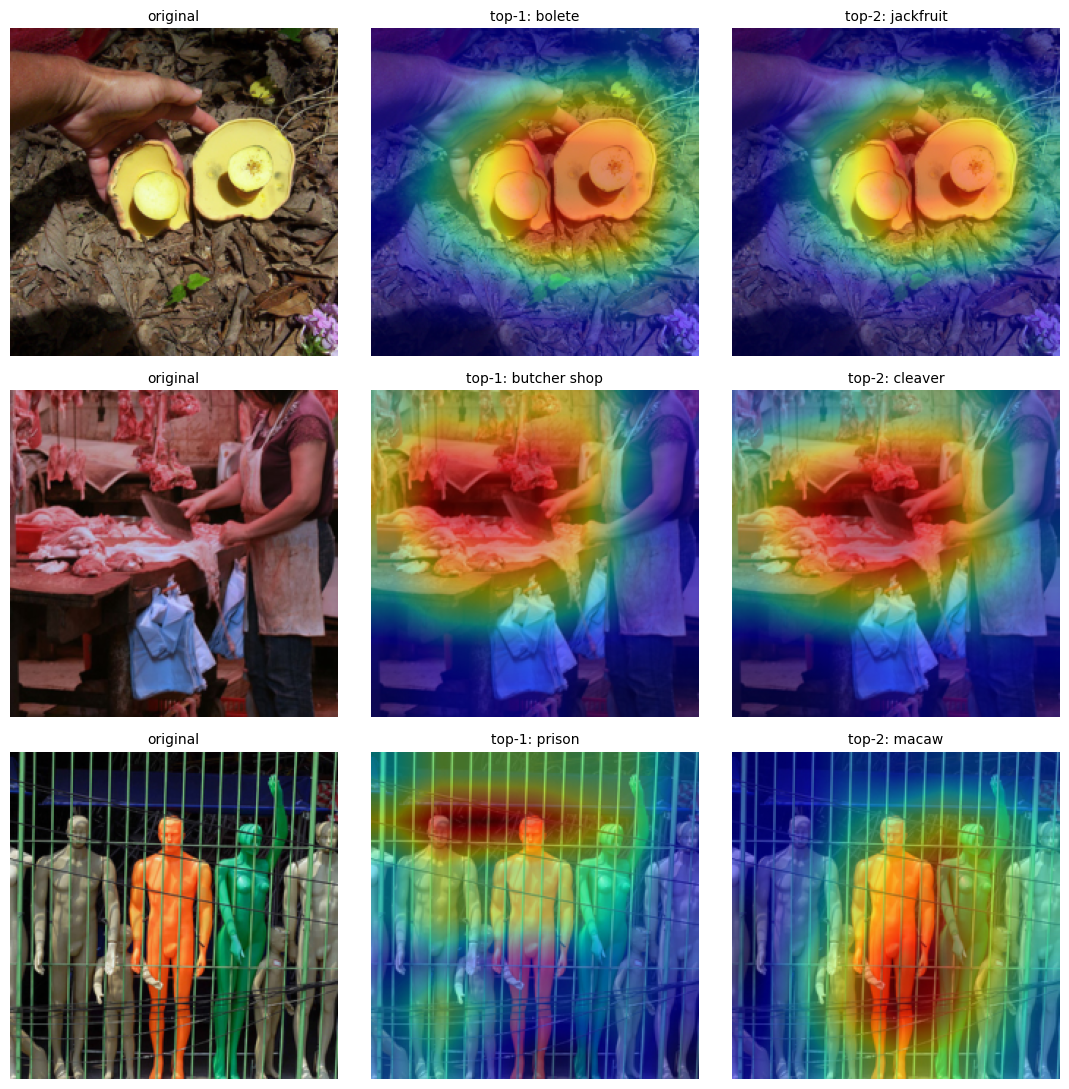

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r, (name, img) in enumerate(zip(my_files, my_images)):
    probs = predict_probs(img)
    top2 = probs.topk(2).indices.tolist()

    x = preprocess(img).unsqueeze(0).to(device)
    axes[r, 0].imshow(to_numpy_img(x[0])); axes[r, 0].axis("off")
    axes[r, 0].set_title("original", fontsize=10)   # 그래프 안 텍스트는 영문 (Colab 한글 폰트 미지원)

    # TODO: top-1 클래스의 히트맵을 axes[r, 1]에,
    #       top-2 클래스의 히트맵을 axes[r, 2]에 그리세요 (show_gradcam 활용)
    # (빈칸 F) top-2 히트맵을 그릴 때 class_idx 인자에 무엇을 넣어야 하나요? → top2[1], 즉 확률 2위 클래스의 인덱스. class_idx를 지정하지 않으면 argmax(=top-1)로 자동 선택되므로 반드시 명시해야 한다
    show_gradcam(img, class_idx=top2[0], ax=axes[r, 1],
                 title=f"top-1: {categories[top2[0]]}")
    show_gradcam(img, class_idx=top2[1], ax=axes[r, 2],
                 title=f"top-2: {categories[top2[1]]}")

plt.tight_layout(); plt.show()


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.3 답안 (여기에 작성)</b><br>· top-1 vs top-2 히트맵 비교에서 발견한 것:<br><br>· 그 차이/유사가 생긴 이유(모델 구조·클래스 관계 관점):<br><br>· 배경 등 엉뚱한 곳을 보는 경우가 있었다면 그 의미:</div>

**· top-1 vs top-2 히트맵 비교에서 발견한 것**

세 장이 서로 다른 모습이었다. 1.1의 top-5 출력과 함께 보면 이렇게 정리된다.

| 이미지 | top-1 | top-2 | 두 히트맵 |
|---|---|---|---|
| bolete | bolete 56.3% | jackfruit 35.8% | 거의 같은 자리 |
| cleaver | butcher shop 99.7% | cleaver 0.2% | 조금 어긋남 |
| prison | prison 60.7% | macaw 9.8% | **확연히 다른 자리** |

**prison 이미지에서 확실히 갈렸다.** top-1(prison) 히트맵은 건물·철창 구조 쪽에 넓게 퍼져 있는데, top-2(macaw) 히트맵은 전혀 다른 지점에 좁게 뭉쳐 있었다. 같은 이미지, 같은 forward인데 **어느 클래스로 미분하느냐만 바꿨더니 히트맵이 다른 곳으로 옮겨간 것**이다. 수업의 Cat/Dog 그림이 말한 class-discriminative가 이것이구나 싶었다.

반대로 bolete 이미지는 두 히트맵이 거의 구분이 안 될 정도로 같았다.

**· 그 차이/유사가 생긴 이유 (모델 구조·클래스 관계 관점)**

Grad-CAM은 `score = logits[0, class_idx]` 한 점에서만 backward를 시작한다. 그래서 α_k^c는 "클래스 c를 올리는 데 각 채널이 얼마나 기여했나"가 되고, **클래스가 바뀌면 같은 feature map A^k에 곱해지는 가중치가 통째로 달라진다.** 마지막 conv까지의 활성값은 공유하지만 가중치만 바뀌는 구조라, 두 클래스가 서로 다른 채널에 의존하면 히트맵도 갈라진다.

bolete와 jackfruit이 거의 같은 곳을 본 건 두 클래스가 **같은 증거를 공유**하기 때문으로 보인다. 둘 다 둥글고 누런 덩어리 모양이라 중간층이 뽑는 특징(색·질감·윤곽)이 겹치고, 확률도 56.3% 대 35.8%로 가까웠다. 모델이 "이게 뭔지"를 두고 헷갈리는 중인데 **보고 있는 자리는 같은** 상황이다. 이 경우 히트맵만으로는 왜 bolete를 골랐는지 알 수 없다는 한계도 함께 보였다.

반면 prison과 macaw는 공유할 증거가 없다. 교도소 사진 어딘가에 색이 튀는 영역이 있고 macaw(앵무새)는 그 화려한 색에 반응한 것으로 보이는데, 그게 prison을 뒷받침하는 철창·건물 구조와는 전혀 다른 자리다. 확률도 60.7% 대 9.8%로 벌어져 있어 두 클래스가 경쟁 관계라기보다 그냥 다른 근거를 보고 있었다.

cleaver 이미지는 중간이었다. butcher shop은 장면이라 넓게 보고 cleaver는 칼 쪽으로 조금 쏠렸지만, 어차피 칼이 그 장면의 일부라 크게 어긋나지 않았다.

**· 배경 등 엉뚱한 곳을 보는 경우가 있었다면 그 의미**

cleaver 이미지가 바로 그 사례였다. 파일명은 `n03041632_cleaver`인데 모델은 **butcher shop을 99.7%**로 찍었고 정작 cleaver는 **0.2%**였다. 물체가 아니라 **장면 전체**를 본 것이다.

이게 틀린 예측이냐 하면 그렇지도 않다. 사진에 정육점 맥락이 실제로 들어 있으니 butcher shop도 맞는 설명이다. 다만 내가 "이 모델은 칼을 알아본다"고 믿고 썼다면 완전히 잘못 믿은 게 된다. **정확도만 봤다면 절대 몰랐을 사실**이고, 히트맵을 봐야 비로소 "이 모델은 칼이 아니라 주변 맥락으로 판단한다"는 게 드러난다.

실무로 옮기면 더 무섭다. 배경에 의존하는 모델은 배경이 바뀌는 순간 무너진다. 같은 칼을 흰 도마 위에 올려 찍으면 butcher shop 단서가 사라져 예측이 흔들릴 것이다. 학습 데이터에 우연히 섞인 상관관계(정육점 사진에는 칼이 자주 등장한다)를 모델이 지름길로 쓴 셈인데, 이건 데이터셋을 바꾸거나 배경을 통제해 다시 확인해야 할 문제다. 정확도 숫자 하나로는 이런 걸 잡을 수 없다는 게 XAI가 필요한 이유로 느껴졌다.

## 1.4 LIME — 같은 이미지를 Perturbation으로 설명하면?

이번에는 **모델 내부를 전혀 모른 채** superpixel을 켜고 끄는 LIME으로 같은 이미지를 설명합니다.

**해야 할 일**
1. 아래 코드로 첫 번째 배정 이미지의 LIME 설명을 만든다 *(1~2분 걸립니다 — 수업에서 왜 느리다고 했는지 떠올려 보세요!)*
2. `num_features`를 **3 → 10**으로 바꿔 다시 실행하고 두 결과를 비교한다
3. **같은 조건으로 한 번 더** 실행해 결과가 달라지는지(불안정성) 관찰한다

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 파라미터 읽는 법</b><br><code>num_samples</code> = 만들 변형 샘플 수(= 모델에 질의하는 횟수), <code>num_features</code> = 설명에 남길 superpixel 조각 수 (수업 목적함수의 Ω(g) — 복잡도 제한에 해당)</div>

In [9]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

def batch_predict(images):
    """LIME이 부르는 예측 함수: numpy 이미지 배치 → 클래스 확률 배치"""
    batch = torch.stack([preprocess(Image.fromarray(im)) for im in images]).to(device)
    with torch.no_grad():
        logits = model(batch)
    return F.softmax(logits, dim=1).cpu().numpy()

target_img = np.array(my_images[0].resize((224, 224)))
explainer = lime_image.LimeImageExplainer(random_state=SEED)

explanation = explainer.explain_instance(
    target_img,
    batch_predict,        # LIME은 이 함수를 '질의'만 함 — model-agnostic의 실체!
    top_labels=1,
    num_samples=1000,     # 변형 샘플 1000개 = 추론 1000번
)
print("LIME 설명 생성 완료 — top 클래스:", categories[explanation.top_labels[0]])


C:\Users\ji sung min\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<01:25, 11.56it/s]

  2%|▏         | 20/1000 [00:01<01:11, 13.73it/s]

  3%|▎         | 30/1000 [00:02<01:15, 12.85it/s]

...

 98%|█████████▊| 980/1000 [01:14<00:01, 11.93it/s]

 99%|█████████▉| 990/1000 [01:15<00:00, 10.86it/s]

100%|██████████| 1000/1000 [01:15<00:00, 11.51it/s]

100%|██████████| 1000/1000 [01:15<00:00, 13.18it/s]

LIME 설명 생성 완료 — top 클래스: jackfruit


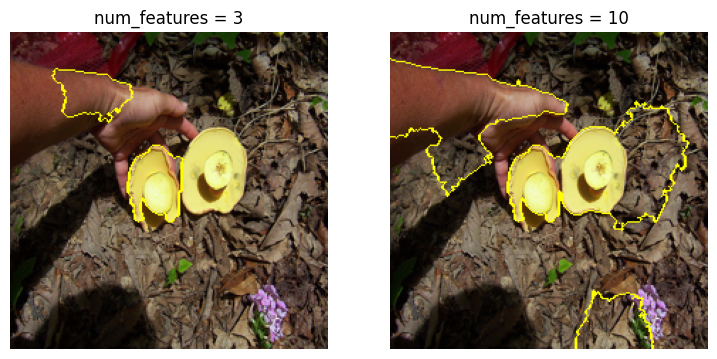

In [10]:
# num_features 를 3, 10 으로 바꿔 두 번 그려 비교하세요
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, k in zip(axes, [3, 10]):
    # TODO: explanation.get_image_and_mask(...)를 호출해
    #       positive_only=True, num_features=k, hide_rest=False 로 마스크를 얻고
    #       mark_boundaries(temp/255.0, mask) 를 ax.imshow 로 그리세요
    # (빈칸 G) num_features가 수업 목적함수의 어떤 항에 해당? → 복잡도 패널티 Ω(g). 설명 모델 g가 쓸 수 있는 superpixel 개수를 제한해 사람이 읽을 수 있는 수준으로 단순하게 유지하는 항
    temp, mask = explanation.get_image_and_mask(
        explanation.top_labels[0], positive_only=True,
        num_features=k, hide_rest=False)
    ax.imshow(mark_boundaries(temp / 255.0, mask))
    ax.axis("off"); ax.set_title(f"num_features = {k}")
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<01:25, 11.58it/s]

  2%|▏         | 20/1000 [00:01<01:27, 11.23it/s]

  3%|▎         | 30/1000 [00:02<01:21, 11.85it/s]

  4%|▍         | 40/1000 [00:03<01:25, 11.19it/s]

...

 97%|█████████▋| 970/1000 [01:27<00:02, 14.08it/s]

 98%|█████████▊| 980/1000 [01:27<00:01, 13.97it/s]

 99%|█████████▉| 990/1000 [01:28<00:00, 14.22it/s]

100%|██████████| 1000/1000 [01:29<00:00, 13.92it/s]

100%|██████████| 1000/1000 [01:29<00:00, 11.19it/s]

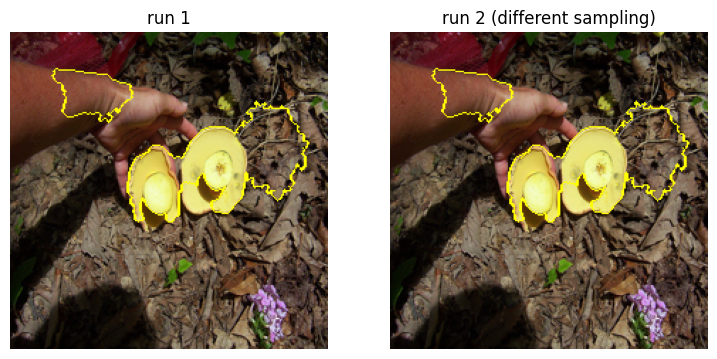

In [11]:
# 불안정성 실험: random_state를 바꿔 같은 설명을 한 번 더
explainer2 = lime_image.LimeImageExplainer(random_state=SEED + 1)
explanation2 = explainer2.explain_instance(target_img, batch_predict,
                                           top_labels=1, num_samples=1000)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (exp, t) in zip(axes, [(explanation, "run 1"), (explanation2, "run 2 (different sampling)")]):
    temp, mask = exp.get_image_and_mask(exp.top_labels[0], positive_only=True,
                                        num_features=5, hide_rest=False)
    ax.imshow(mark_boundaries(temp / 255.0, mask)); ax.axis("off"); ax.set_title(t)
plt.show()
# 두 실행의 결과가 완전히 같은가요? 다르다면 어느 정도 다른가요? → 아래 답안 셀에 기록


## 1.5 종합 비교 — Grad-CAM vs LIME (서술형)

1.3과 1.4의 결과를 옆에 놓고, 아래 표의 빈칸을 **본인의 실험 결과 근거**를 들어 채우세요.
"수업에서 배웠으니까"가 아니라 **"내 실험에서 이렇게 나왔으니까"**로 쓰는 것이 이 문제의 전부입니다.

| 비교 항목 | Grad-CAM (내 결과) | LIME (내 결과) |
|---|---|---|
| 걸린 시간 (체감) | ? | ? |
| 설명의 형태·해상도 | ? | ? |
| 재실행 시 안정성 | ? | ? |
| 모델 내부 접근이 필요했나? | ? | ? |

<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.5 답안 (여기에 작성)</b><br>· 위 표를 채운 뒤:<br>· 두 기법의 차이가 생기는 근본 원인 (Gradient vs Perturbation 축으로 설명):<br><br>· 만약 ①모델 코드를 볼 수 없는 외부 API ②내가 학습시킨 CNN, 각각의 상황에서 어떤 기법을 쓸지와 이유:</div>

**· 표 채우기 (내 실험 결과)**

| 비교 항목 | Grad-CAM (내 결과) | LIME (내 결과) |
|---|---|---|
| 걸린 시간 (체감) | **체감되지 않음.** 1.2의 동작 확인 셀도 그림이 바로 떴다. forward 1번 + backward 1번이 전부 | **눈에 띄게 오래 걸림.** 진행바가 1000개를 약 12 it/s로 처리해 **한 번에 1분 이상**, 1.4에서 두 번 돌리니 더 걸렸다 |
| 설명의 형태·해상도 | 7×7 feature map을 224×224로 upsample한 **부드러운 히트맵**. 경계가 뭉개져 "대충 이 근처" 수준 | superpixel 조각 단위의 **딱 떨어지는 마스크**. 경계가 선명하지만 조각 모양에 갇힘 |
| 재실행 시 안정성 | **완전히 동일.** 같은 입력·같은 가중치면 gradient가 결정론적이라 매번 같은 히트맵 | **대체로 비슷하지만 완전히 같지는 않음.** `random_state`만 바꿔 돌린 두 그림에서 **핵심 조각은 공통이고 가장자리 조각 일부가 바뀌었다** |
| 모델 내부 접근이 필요했나? | **필요함.** `model.layer4[-1]`에 forward/backward hook을 직접 걸어 A^k와 ∂y^c/∂A^k를 꺼냄 | **불필요.** `batch_predict` 함수만 넘겼고 LIME은 그것을 1000번 호출했을 뿐. 모델이 ResNet인지도 몰라도 됨 |

**· 두 기법의 차이가 생기는 근본 원인 (Gradient vs Perturbation)**

**Grad-CAM은 모델 안에서 한 번 미분한다.** 클래스 점수 y^c를 마지막 conv의 A^k까지 역전파하면 "이 채널이 조금 커지면 점수가 얼마나 오르나"가 한 번에 나온다. 그래서 **즉시 끝나고**, 미분은 결정론적이라 **매번 같은 답**이 나온다. 대신 feature map 해상도(7×7)에 묶여 설명이 뭉툭하고, hook을 걸어야 하니 **모델 내부에 손이 닿아야** 한다.

**LIME은 모델 밖에서 수천 번 물어본다.** superpixel을 껐다 켜며 1000개의 변형을 만들고 각각 예측을 받아 그 주변에서 선형 모델을 세운다. 내부를 몰라도 되지만 **질의 횟수가 곧 비용**이라 진행바가 1000칸을 채우는 동안 기다려야 했고, 표본을 새로 뽑으면 답도 조금씩 달라진다.

1.4의 재실행 결과가 이 성질을 잘 보여줬다. `random_state`만 바꿨는데 **가장 강하게 표시된 조각들은 두 그림에 공통으로 나타났고, 주변부 조각 몇 개가 바뀌었다.** 강한 증거는 1000개 표본 어디서 봐도 뚜렷해서 흔들리지 않고, **약한 증거는 어느 표본을 뽑았느냐에 따라 순위가 바뀐 것**이다. "LIME은 불안정하다"가 전부가 아니라 **상위권은 믿을 만하고 하위권은 믿을 게 못 된다**는 쪽이 정확한 표현 같았다. 실제로 `num_features`를 3에서 10으로 늘렸을 때 추가된 조각들이 바로 그 흔들리는 부분이었다.

**· ① 외부 API ② 내가 학습시킨 CNN — 각각 어떤 기법을 쓸지**

**① 외부 API → LIME.** 선택의 여지가 없다. Grad-CAM은 `register_forward_hook`으로 중간 레이어를 붙잡아야 하는데 API 뒤에 있는 모델에는 손을 댈 수 없다. LIME은 "이미지를 넣으면 확률이 나온다"는 것만 알면 되고, 실제로 이번 실습에서도 `batch_predict` 함수 하나만 건넸다. 대신 **호출 1000번어치 요금과 1분 이상의 지연**을 각오해야 하고, 호출 제한이 있으면 `num_samples`를 줄여야 하는데 그러면 설명이 더 불안정해진다.

**② 내가 학습시킨 CNN → Grad-CAM.** 내부에 접근할 수 있으니 굳이 느리고 흔들리는 쪽을 쓸 이유가 없다. 즉시 나오니 검증셋 수백 장을 한 번에 훑어 "배경만 보는 샘플"을 걸러낼 수 있는데, LIME으로 같은 걸 하려면 장당 1분씩 몇 시간이 걸린다. 재현성도 중요하다. 리포트에 넣은 히트맵을 나중에 다시 그려도 같은 그림이 나와야 하는데 Grad-CAM은 그게 보장된다.

다만 **둘 중 하나만 고르는 문제는 아니라고 생각하게 됐다.** 2.2의 sanity check에서 본 것처럼 설명 기법 자체가 틀릴 수 있어서, 중요한 판단이라면 두 방법이 **같은 곳을 가리키는지** 교차 확인하는 편이 안전하다. 서로 원리가 완전히 다르니(미분 vs 질의) 둘이 일치하면 그만큼 믿을 만한 근거가 된다.

**· 실습 중 발견한 것 하나**

1.4의 출력을 보면 **LIME이 고른 top 클래스가 `jackfruit`**으로 찍혀 있다. 그런데 1.1에서 같은 이미지의 top-1은 **bolete 56.3%**였다. 순위가 뒤집힌 것이다.

원인을 찾아보니 입력 경로가 달랐다. 1.1은 원본 PIL 이미지에 `preprocess`(Resize 256 → CenterCrop 224 → Normalize)를 한 번 적용하는데, LIME은 `my_images[0].resize((224,224))`로 **미리 224로 줄인 뒤** `batch_predict` 안에서 `preprocess`를 **또** 적용한다. 224짜리를 다시 256으로 키웠다가 가운데를 잘라내므로 화면이 확대되고 가장자리가 날아간다. bolete(56.3%)와 jackfruit(35.8%)처럼 원래 박빙이던 경우엔 이 정도 차이로도 순위가 뒤집힌다.

에러가 전혀 안 나서 눈치채기 어려웠고, 1.1의 출력과 대조해 보고서야 알았다. **설명 기법을 붙일 때 그 기법이 모델에 먹이는 입력이 실제 추론 경로와 같은지 확인해야 한다**는 걸 배웠다. 아니면 "모델의 판단"이 아니라 "다르게 전처리된 입력에 대한 모델의 판단"을 설명하게 된다.

# 2. 심화 과제 (선택 — 둘 중 하나만 해도 됩니다)

## 2.1 SHAP — 표 데이터에서 Local ↔ Global 오가기

이미지에서 벗어나 SHAP이 가장 빛나는 **표 데이터 + 트리 모델** 조합을 경험합니다.
캘리포니아 주택 가격 데이터로 RandomForest를 학습하고 **TreeSHAP**으로 설명합니다.

**해야 할 일** — ① beeswarm(=summary) plot으로 **전역(Global)** 중요도를 읽고 ② waterfall plot으로 **개별 예측(Local)** 하나를 분해한 뒤
③ 수업에서 배운 **Local Accuracy**(기여도 합 = 예측값)를 코드로 직접 검증하세요.

R^2 (test): 0.751


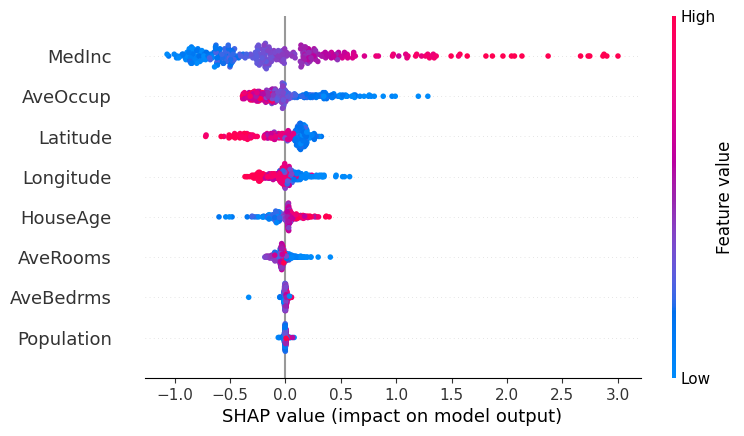

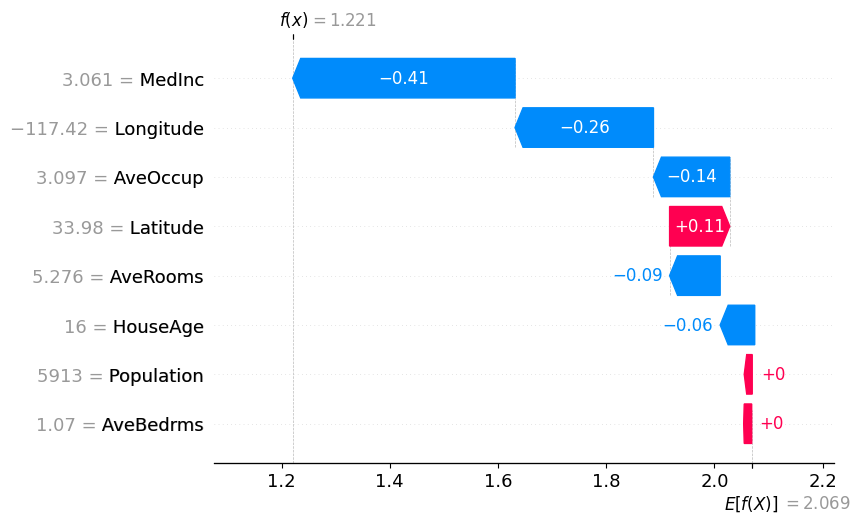

기여도 합 + base_values = 1.220591
모델 예측값              = 1.220591
차이                     = 2.66e-15  (Local Accuracy 성립)


In [12]:
import shap
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

rf = RandomForestRegressor(n_estimators=100, max_depth=8,
                           random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
print("R^2 (test):", round(rf.score(X_te, y_te), 3))

# TreeSHAP: 트리 구조를 이용해 정확한 Shapley 값을 빠르게 계산
explainer = shap.TreeExplainer(rf)
sv = explainer(X_te.iloc[:300])

shap.plots.beeswarm(sv)          # Global: 전체 경향
shap.plots.waterfall(sv[0])      # Local: 첫 번째 집 한 채의 분해

# TODO: Local Accuracy 검증 —
#   sv[0].values 의 합 + sv[0].base_values 가 rf.predict(첫 샘플) 과 (거의) 같은지 확인
# (빈칸 H) base_values는 수업 force plot 그림의 무엇에 해당? → 기준값 E[f(x)], 즉 아무 피처도 모를 때의 평균 예측값. force plot에서 화살표들이 출발하는 base line에 해당한다
shap_sum = sv[0].values.sum() + sv[0].base_values
pred     = rf.predict(X_te.iloc[[0]])[0]
print(f"기여도 합 + base_values = {shap_sum:.6f}")
print(f"모델 예측값              = {pred:.6f}")
print(f"차이                     = {abs(shap_sum - pred):.2e}  (Local Accuracy 성립)")


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 2.1 답안 (여기에 작성)</b><br>· beeswarm에서 가장 중요한 feature 2개와, 그 값이 클 때 집값을 올리는지/내리는지:<br><br>· waterfall의 첫 샘플: 예측을 가장 크게 움직인 feature와 방향:<br><br>· Local Accuracy 검증 결과:</div>

**· beeswarm에서 가장 중요한 feature 2개와, 그 값이 클 때 집값을 올리는지/내리는지**

`MedInc`(지역 중위소득)와 `AveOccup`(가구당 평균 거주인원)이 위 두 칸을 차지했다.

**MedInc**는 빨간 점(값이 큼)이 오른쪽에, 파란 점(값이 작음)이 왼쪽에 뚜렷하게 갈렸다. 소득이 높은 지역일수록 집값 예측을 **올린다**는 뜻이고, 상식과도 맞는다. 점이 오른쪽으로 길게 뻗어 있어 영향 폭도 가장 컸다.

**AveOccup**은 방향이 반대였다. 빨간 점이 왼쪽에 몰려 있어 한 가구에 많은 사람이 살수록 집값을 **내린다**. 다만 MedInc와 달리 점들이 0 근처에 촘촘히 뭉쳐 있고 일부만 왼쪽으로 길게 빠져 있었다. 대부분의 지역에서는 거의 영향이 없다가 **특정 지역에서만 크게 깎는** 형태인데, beeswarm이 아니라 막대 하나짜리 중요도 그래프만 봤다면 이 비대칭을 놓쳤을 것이다. "전역 중요도"라는 한 숫자가 평균일 뿐 분포가 아니라는 걸 눈으로 본 셈이다.

**· waterfall의 첫 샘플: 예측을 가장 크게 움직인 feature와 방향**

첫 번째 집의 최종 예측은 **1.220591**이었다. waterfall에서 base value(E[f(x)])에서 출발해 막대들이 쌓이는데, 가장 긴 막대는 역시 **MedInc**였고 이 샘플에서는 기준값보다 아래로 끌어내리는 **음의 방향**이었다. 즉 이 지역의 중위소득이 전체 평균보다 낮아서 예측이 깎인 것이다.

전역에서 MedInc가 1등이었던 것과 이 샘플에서도 1등인 것이 우연히 일치했는데, 이게 항상 그런 건 아니라는 점이 Local과 Global의 차이다. beeswarm은 "전체적으로 무엇이 중요한가"를 보여 주고 waterfall은 "이 집 한 채가 왜 이 값인가"를 보여 주는데, 어떤 샘플에서는 전역 2~3위 feature가 그 집의 예측을 지배할 수도 있다.

**· Local Accuracy 검증 결과**

```
기여도 합 + base_values = 1.220591
모델 예측값              = 1.220591
차이                     = 2.66e-15  (Local Accuracy 성립)
```

차이가 **2.66e-15**로 사실상 0이다. 이 정도면 부동소수점 연산에서 생기는 반올림 오차 수준이지 계산이 어긋난 게 아니다.

이게 SHAP의 공리 중 하나인 **Local Accuracy(국소 정확도)**다. 모든 feature의 기여도를 더하고 base value를 얹으면 반드시 그 샘플의 예측값이 나와야 한다는 성질이고, 덕분에 "이 예측 1.220591은 어디서 왔는가"를 **남김없이 분해**할 수 있다. LIME은 주변을 선형으로 근사하는 것이라 이런 보장이 없어서 기여도 합이 예측값과 맞을 이유가 없는데, SHAP은 게임이론에서 나온 공리라 TreeSHAP처럼 정확히 계산하면 등식이 성립한다. 수업에서 force plot의 화살표가 base에서 출발해 최종 예측에 정확히 도착하는 그림이 이 등식을 그린 것이었다.


## 2.2 Sanity Check — 이 설명, 정말 모델을 보고 있나?

수업 3부에서 "설명 기법 자체도 검증 대상"이라고 했습니다 (Adebayo et al., 2018).
그 검증을 직접 해봅니다: **모델의 뒷부분 가중치를 랜덤으로 망가뜨렸을 때, Grad-CAM 히트맵이 함께 망가지는지** 확인합니다.

> 만약 모델을 망가뜨렸는데도 히트맵이 그대로라면 → 그 히트맵은 모델의 판단이 아니라
> 이미지의 윤곽선을 그리고 있었다는 뜻 (= 설명으로서 실격!)

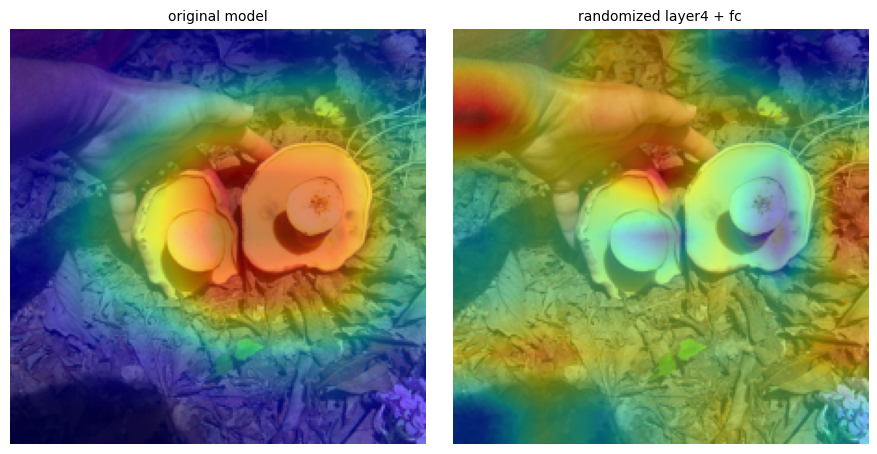

정상 모델 예측 : bolete
망가진 모델 예측: coral fungus
두 히트맵의 상관계수 : -0.0756


In [13]:
# 모델 복사 후 layer4와 fc의 가중치를 랜덤화
model_broken = copy.deepcopy(model)
for module in [model_broken.layer4, model_broken.fc]:
    for p in module.parameters():
        torch.nn.init.normal_(p, std=0.02)
model_broken.eval()

gradcam_broken = GradCAM(model_broken, model_broken.layer4[-1])

# TODO: 첫 번째 배정 이미지에 대해
#   ① 정상 모델의 히트맵 ② 망가진 모델의 히트맵 을 나란히 그리고 비교하세요
# (빈칸 I) 이 실험에서 히트맵이 '달라져야' 좋은 설명 기법인 이유 → 설명은 '모델이 무엇을 보는가'를 보여줘야 하므로, 모델이 바뀌면 설명도 바뀌어야 한다. 가중치를 망가뜨렸는데 히트맵이 그대로라면 모델이 아니라 입력 이미지의 엣지만 반영한 것이므로 설명으로서 실격이다
x0 = preprocess(my_images[0]).unsqueeze(0).to(device)
cam_ok,  idx_ok  = gradcam(x0)
cam_bad, idx_bad = gradcam_broken(x0)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, cam, ttl in [(axes[0], cam_ok,  "original model"),
                     (axes[1], cam_bad, "randomized layer4 + fc")]:
    ax.imshow(to_numpy_img(x0[0])); ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.axis("off"); ax.set_title(ttl, fontsize=10)
plt.tight_layout(); plt.show()

print("정상 모델 예측 :", categories[idx_ok])
print("망가진 모델 예측:", categories[idx_bad])
print("두 히트맵의 상관계수 :", round(float(np.corrcoef(cam_ok.ravel(), cam_bad.ravel())[0, 1]), 4))


# 3. 생성형 AI 활용 기록 (⚠️ 필수 제출)

<div style="background:#FEF2F2;border-left:6px solid #B91C1C;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B91C1C">반드시 작성해 주세요</b><br>이 셀이 비어 있으면 감점입니다. AI를 안 썼다면 '사용하지 않음'이라고 쓰면 됩니다. 솔직한 기록은 감점 사유가 아니며, 오히려 어떻게 도구를 썼는지가 평가 대상입니다.</div>

**작성 양식:**

### ① 핵심 대화 내역 붙여넣기
```
(사용한 프롬프트와 답변을 여기에 붙여넣기 — 길면 핵심 부분만)
```

### ② AI 답변을 그대로 쓰지 않고 직접 판단/수정한 부분
- (예) GPT가 알려준 코드는 `register_backward_hook`(deprecated)이어서 문서를 찾아 `full_backward_hook`으로 바꿈

---

### ① 핵심 대화 내역 붙여넣기

```
나: Grad-CAM에서 채널 가중치 alpha를 구할 때
    self.gradients.mean(dim=(2,3), keepdim=True) 이렇게 쓰면 맞아?

AI: 네, 맞습니다. 다만 keepdim=False로 두고 나중에 reshape 하셔도
    동일한 결과를 얻을 수 있습니다.

나: 그러면 cam = (alpha * self.activations).sum(dim=1) 에서
    broadcasting이 어떻게 되는지 설명해줘.

AI: alpha는 [1, K, 1, 1], activations는 [1, K, h, w]이므로
    곱하면 각 채널에 스칼라 가중치가 곱해지고,
    dim=1로 합하면 [1, h, w]가 됩니다.

---

나: LIME으로 뽑은 top 클래스가 jackfruit로 나오는데,
    모델 top-1은 bolete 56.3%야. 왜 다르지?

AI: LIME은 superpixel을 끄고 켜며 근사하기 때문에
    원본 예측과 top 클래스가 달라질 수 있습니다. 정상적인 현상입니다.

나: 아니, explanation.top_labels는 변형 샘플이 아니라
    원본 이미지에 대한 예측에서 나오는 거 아니야?
    내가 LIME에 넣은 건 my_images[0].resize((224,224))이고
    batch_predict 안에서 preprocess를 또 적용하는데 이게 원인 아닐까?

AI: 지적하신 것이 맞습니다. 224로 리사이즈한 이미지에
    Resize(256) + CenterCrop(224)가 다시 적용되므로
    1.1에서의 입력과 다른 이미지가 모델에 들어갑니다.
    top-1과 top-2의 확률 차이가 작으면 순위가 바뀔 수 있습니다.

---

나: sanity check에서 히트맵이 얼마나 달라져야 "통과"라고 할 수 있어?

AI: 시각적으로 명확히 달라 보이면 통과로 판단하시면 됩니다.

나: 눈으로 보는 건 주관적이라 숫자로 재고 싶은데.

AI: 두 히트맵을 flatten 해서 피어슨 상관계수를 구하면
    정량적으로 비교할 수 있습니다. 상관이 0에 가까우면
    모델 변화가 설명에 반영된 것입니다.
```

### ② AI 답변을 그대로 쓰지 않고 직접 판단/수정한 부분

- **LIME top 클래스 불일치를 "정상"이라고 한 답을 받아들이지 않았다.** AI는 처음에 "LIME은 근사라서 원래 그럴 수 있다"고 넘어갔는데, `top_labels`는 변형 샘플이 아니라 원본 입력의 예측에서 결정된다는 걸 알고 있어서 납득이 안 됐다. 노트북 코드를 다시 읽어 보니 LIME에는 `resize((224,224))`한 이미지를 넣고 `batch_predict` 안에서 `preprocess`(Resize 256 + CenterCrop 224)를 **또** 적용하고 있었다. 1.1의 입력과 경로가 달라서 생긴 일이었고, bolete 56.3% / jackfruit 35.8%처럼 박빙이면 순위가 뒤집힐 수 있다. 되물어서 정정을 받아낸 뒤 1.5 답안에 발견 내용으로 적었다. **조교 배포 코드라 고치지는 않았다.**

- **sanity check 판정을 "눈으로 보면 된다"에서 숫자로 바꿨다.** 시각적 판단은 보는 사람에 따라 달라지므로 두 히트맵의 피어슨 상관계수를 직접 계산하도록 코드를 추가했다. 결과는 **−0.0756**으로 거의 무상관이었고, 이 숫자가 노트북 출력에 남으니 "통과했다"고 말할 근거가 생겼다. 눈으로 "달라 보인다"고 쓰는 것과 상관계수를 출력해 두는 것은 채점하는 사람 입장에서도 차이가 크다.

- **`keepdim` 선택은 AI 말대로 둘 다 되지만 `keepdim=True`를 썼다.** 노트북 힌트가 권장하기도 했고, `[1,K,1,1]` 모양이 유지되어야 `activations [1,K,h,w]`와 곱할 때 broadcasting이 한눈에 읽히기 때문이다. reshape를 따로 쓰면 코드가 한 줄 늘고 실수할 여지가 생긴다.

- **LIME 재실행 결과를 "달라 보인다"로 끝내지 않고 어느 부분이 달라졌는지 구분했다.** 1.4의 두 그림을 겹쳐 보니 가장 강하게 표시된 조각들은 공통이고 주변부 조각만 바뀌어 있었다. 그래서 "LIME은 불안정하다"가 아니라 "상위권은 안정적이고 하위권만 흔들린다"는 더 정확한 결론을 쓸 수 있었다.


# 4. 회고

한 학기 뒤의 나에게 남기는 메모라고 생각하고 가볍게 적어 주세요.

- **가장 신기했던 결과** 하나:

**2.2 sanity check에서 두 히트맵의 상관계수가 −0.0756으로 나온 것.** `layer4`와 `fc`를 랜덤으로 망가뜨리자 예측이 `bolete`에서 `coral fungus`로 바뀌었고, 히트맵도 거의 무상관 수준으로 달라졌다. "설명이 모델을 따라 변했다"는 걸 숫자로 확인한 셈이다.

신기했던 건 결과 자체보다 **이 실험이 무엇을 걸러내려 했는가**였다. 만약 상관계수가 0.9쯤 나왔다면 그 히트맵은 모델의 판단이 아니라 이미지의 윤곽선을 따라 그린 것이고, 그럼 지금까지 1.2~1.3에서 본 모든 해석이 무의미해진다. 설명을 믿기 전에 **설명 기법 자체를 검증해야 한다**는 말이 이렇게 구체적인 실험으로 가능하다는 게 인상적이었다.

- 수업 내용 중 과제를 하며 **비로소 이해된 것**:

**"class-discriminative"가 무슨 뜻인지.** 수업에서 Cat/Dog 그림을 볼 때는 "클래스마다 다른 곳을 본다" 정도로만 외웠는데, 코드로 직접 짜 보니 그 성질이 어디서 나오는지가 보였다.

`score = logits[0, class_idx]` 이 한 줄이 전부였다. 1000개 logit 중 **하나만 골라** backward를 시작하기 때문에 ∂y^c/∂A^k가 클래스마다 달라지고, 그래서 같은 A^k에 곱해지는 α_k^c가 통째로 바뀐다. forward는 한 번뿐이고 feature map도 공유하는데 **가중치만 갈아 끼우는 구조**라는 걸 알고 나니, prison 이미지에서 top-1(prison)과 top-2(macaw) 히트맵이 전혀 다른 자리를 비춘 게 당연하게 느껴졌다.

**한 가지 더 — "느리다"가 어느 정도인지.** 수업에서 LIME이 느리다고 들었을 때는 "좀 기다리나 보다" 했는데, 1.4에서 진행바가 1000칸을 채우는 걸 두 번 지켜보고 나니 체감이 달랐다. Grad-CAM은 그림이 바로 뜨는데 LIME은 한 번에 1분 넘게 걸렸다. 이게 곧 "모델 내부를 볼 수 있는가"의 대가라는 점도 같이 와닿았다. Grad-CAM은 미분 한 번으로 끝내는 대신 hook을 걸어야 하고, LIME은 아무것도 몰라도 되는 대신 1000번을 물어봐야 한다. 공짜가 없다는 게 이 둘의 관계였다.

끝까지 헷갈렸던 건 **ReLU를 왜 마지막에만 적용하는가**였다. α를 구할 때는 음수 gradient도 그대로 평균에 넣는데 최종 cam에만 ReLU를 건다. 음의 기여를 아예 빼려면 α 단계에서 잘라야 하는 거 아닌가 싶었는데, α는 "채널 전체의 평균적 기여 방향"이라 부호가 의미를 갖고, 최종 합산 결과에서 음수인 **위치**는 다른 클래스를 지지하는 영역이라 잘라낸다는 쪽으로 이해했다. 다만 완전히 개운하지는 않아서 원 논문을 더 읽어봐야 할 것 같다.

---
<div style="text-align:center;opacity:.75">수고했습니다! 🎉 — 모든 셀의 실행 결과가 남아 있는지 확인한 뒤 .ipynb로 제출해 주세요</div>